# ⚡ DA-018 · Energy Analytics: Campus Electricity Usage Patterns

**Business question.** A facility manager wants to know *when* the campus uses the most electricity, *where* (which area), how weekdays differ from weekends, and which readings look unusual enough to investigate.

**Dataset (synthetic, generated by `src/generate_campus_data.py`)**

| Item | Value |
|---|---|
| Period | 1 Jan 2023 – 31 Dec 2023 |
| Areas (meters) | Academic Block, Library, Hostel, Computer Labs |
| Sampling interval | 15 minutes (expected 96 readings per area per day) |
| Unit | `consumption_kwh` = energy used **during that 15-min interval** (kWh). Average power (kW) = kWh × 4 |

The data deliberately contains realistic problems (missing intervals, duplicates, negative readings, spikes, equipment left on) so the cleaning and outlier steps have real work to do.

> **Using Google Colab?** Upload `data/campus_energy_readings.csv` and change `DATA` in the next cell to its path.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.1f}".format

# ---- configuration (all analysis assumptions live here) -------------------
EXPECTED_INTERVAL = pd.Timedelta("15min")
INTERVALS_PER_DAY = 96          # 24 h x 4
KW_FACTOR = 4                   # kWh per 15 min  ->  average kW
MAX_GAP = 4                     # only gaps of <= 4 intervals (1 hour) are interpolated
Z_THRESH = 6.0                  # robust z-score threshold for unusual readings
MIN_RATIO = 2.0                 # ...and the reading must be >= 2x the typical value
SUSTAINED_MIN_INTERVALS = 4     # >= 1 hour in a row = "sustained" event

# ---- locate (or generate) the data ----------------------------------------
candidates = [Path("../data/campus_energy_readings.csv"), Path("data/campus_energy_readings.csv")]
DATA = next((p for p in candidates if p.exists()), None)
if DATA is None:                                   # first run: create the sample file
    root = Path("..") if Path("../src").exists() else Path(".")
    sys.path.insert(0, str(root.resolve()))
    from src.generate_campus_data import generate_campus
    DATA = root / "data" / "campus_energy_readings.csv"
    generate_campus(out=str(DATA))
print("Using:", DATA)

Using: ..\data\campus_energy_readings.csv


## 1 · Load, parse dates, confirm units and sampling interval

In [2]:
raw = pd.read_csv(DATA, parse_dates=["timestamp"])
print(raw.dtypes, "\n")
print(f"Rows: {len(raw):,}   Areas: {sorted(raw.area.unique())}")
print(f"Range: {raw.timestamp.min()}  ->  {raw.timestamp.max()}")
raw.head()

timestamp          datetime64[us]
area                          str
consumption_kwh           float64
temperature_c             float64
dtype: object 

Rows: 139,642   Areas: ['Academic Block', 'Computer Labs', 'Hostel', 'Library']
Range: 2023-01-01 00:00:00  ->  2023-12-31 23:45:00


,timestamp,area,consumption_kwh,temperature_c
0,2023-01-01 00:00:00,Academic Block,1.9,14.6
1,2023-01-01 00:00:00,Computer Labs,3.0,14.6
2,2023-01-01 00:00:00,Hostel,4.2,14.6
3,2023-01-01 00:00:00,Library,1.5,14.6
4,2023-01-01 00:15:00,Academic Block,1.8,14.8


In [3]:
# Confirm sampling interval per area = most common gap between consecutive timestamps
unique_ts = raw.drop_duplicates(["area", "timestamp"]).sort_values(["area", "timestamp"])
interval = unique_ts.groupby("area")["timestamp"].apply(lambda s: s.diff().mode()[0])
print(interval)
assert (interval == EXPECTED_INTERVAL).all(), "Unexpected sampling interval - check the meter export!"
print("\nConfirmed: 15-minute readings. Unit: kWh per interval (kW = kWh x 4).")

area
Academic Block   0 days 00:15:00
Computer Labs    0 days 00:15:00
Hostel           0 days 00:15:00
Library          0 days 00:15:00
Name: timestamp, dtype: timedelta64[us]

Confirmed: 15-minute readings. Unit: kWh per interval (kW = kWh x 4).


## 2 · Data-quality audit and missing-interval handling

**Policy (stated up front so results are reproducible):**
1. **Duplicates** (same area + timestamp) → keep the first.
2. **Negative readings** are impossible for a consumption meter → treated as *missing*, not as zero.
3. Rebuild the **full 15-min grid** per area so absent rows become visible gaps.
4. **Short gaps (≤ 1 hour)** are linearly interpolated and counted. **Longer gaps are left missing** – we do not invent hours or days of data.
5. A day is a **complete day** only if all 96 intervals exist after step 4. Daily totals and comparisons use complete days only, so gaps can't masquerade as "low usage".

In [4]:
audit = pd.DataFrame({
    "rows_in_file":      raw.groupby("area").size(),
    "duplicate_rows":    raw[raw.duplicated(["area", "timestamp"])].groupby("area").size(),
    "negative_readings": raw[raw.consumption_kwh < 0].groupby("area").size(),
    "null_values":       raw[raw.consumption_kwh.isna()].groupby("area").size(),
}).fillna(0).astype(int)

df = raw.drop_duplicates(["area", "timestamp"]).copy()
df.loc[df.consumption_kwh < 0, "consumption_kwh"] = np.nan

areas = sorted(df.area.unique())
full_index = pd.date_range(df.timestamp.min(), df.timestamp.max(), freq="15min", name="timestamp")
wide = df.pivot(index="timestamp", columns="area", values="consumption_kwh").reindex(full_index)
temperature = df.drop_duplicates("timestamp").set_index("timestamp")["temperature_c"].reindex(full_index)

audit["missing_before_fill"] = wide.isna().sum()
audit

,rows_in_file,duplicate_rows,negative_readings,null_values,missing_before_fill
area,,,,,
Academic Block,34928,2,0,43,157
Computer Labs,34936,2,1,37,144
Hostel,34847,3,4,32,232
Library,34931,3,1,28,141


In [5]:
def fill_short_gaps(s: pd.Series, max_gap: int = MAX_GAP) -> pd.Series:
    """Interpolate only NaN runs no longer than max_gap; leave longer runs untouched.
    (pandas' own `limit=` would fill the *start* of a long gap, which we do not want.)"""
    isna = s.isna()
    run_id = isna.ne(isna.shift(fill_value=False)).cumsum()
    run_len = isna.groupby(run_id).transform("sum")
    short = isna & (run_len <= max_gap)
    interp = s.interpolate(method="time", limit_area="inside")
    out = s.copy()
    out[short] = interp[short]
    return out

filled = wide.apply(fill_short_gaps)

audit["interpolated (<=1h gaps)"] = (wide.isna() & filled.notna()).sum()
audit["still_missing"] = filled.isna().sum()
audit["pct_intervals_usable"] = (filled.notna().mean() * 100).round(2)
audit

,rows_in_file,duplicate_rows,negative_readings,null_values,missing_before_fill,interpolated (<=1h gaps),still_missing,pct_intervals_usable
area,,,,,,,,
Academic Block,34928,2,0,43,157,157,0,100.0
Computer Labs,34936,2,1,37,144,144,0,100.0
Hostel,34847,3,4,32,232,136,96,99.7
Library,34931,3,1,28,141,129,12,100.0


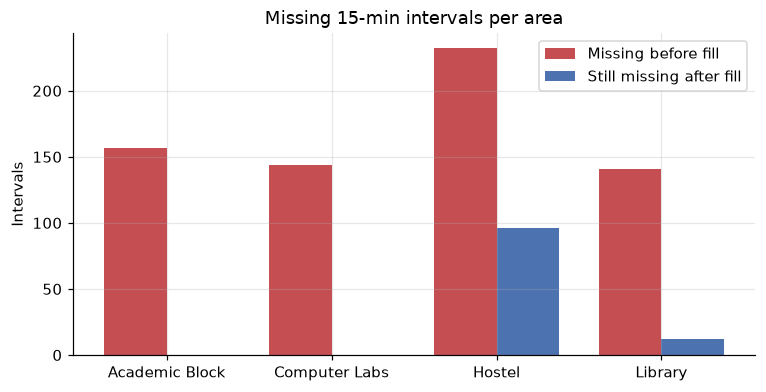

In [6]:
# CHART 1 - data completeness before and after gap handling
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(areas)); w = 0.38
ax.bar(x - w/2, audit.loc[areas, "missing_before_fill"], w, label="Missing before fill", color="#c44e52")
ax.bar(x + w/2, audit.loc[areas, "still_missing"], w, label="Still missing after fill", color="#4c72b0")
ax.set_xticks(x); ax.set_xticklabels(areas)
ax.set(title="Missing 15-min intervals per area", ylabel="Intervals")
ax.legend(); plt.show()

## 3 · Daily and monthly consumption summaries

In [7]:
coverage = filled.notna().astype(float).resample("D").mean()
daily = filled.resample("D").sum(min_count=1)
daily_valid = daily.where(coverage >= 0.999)                      # complete days only
campus_daily = daily_valid[areas].sum(axis=1, min_count=len(areas))   # needs ALL areas complete
dv = daily_valid.assign(Campus=campus_daily)

excluded = (coverage < 0.999)
print("Days excluded (incomplete) per area:")
for a in areas:
    days = [d.strftime("%d %b") for d in excluded.index[excluded[a]]]
    print(f"  {a:15s} {len(days)} day(s) {days}")
print(f"\nCampus-level complete days: {campus_daily.notna().sum()} of {len(campus_daily)}")

Days excluded (incomplete) per area:
  Academic Block  0 day(s) []
  Computer Labs   0 day(s) []
  Hostel          1 day(s) ['14 Aug']
  Library         1 day(s) ['21 Mar']

Campus-level complete days: 363 of 365


In [8]:
avg_daily = dv.resample("MS").mean()            # average kWh per complete day, by month
n_days    = dv.resample("MS").count()           # how many complete days support each average
est_total = avg_daily.mul(avg_daily.index.days_in_month.values, axis=0)

monthly = avg_daily.copy()
monthly.insert(0, "complete_days", n_days["Campus"])
monthly["Campus est. monthly total"] = est_total["Campus"]
monthly.index = monthly.index.strftime("%b %Y")
print("Average kWh per complete day, by month  |  last column = avg daily x days in month (estimate)")
monthly

Average kWh per complete day, by month  |  last column = avg daily x days in month (estimate)


area,complete_days,Academic Block,Computer Labs,Hostel,Library,Campus,Campus est. monthly total
timestamp,,,,,,,
Jan 2023,31,495.4,651.0,580.4,445.2,"2,172.1","67,333.7"
Feb 2023,28,497.2,714.8,580.3,445.7,"2,238.1","62,667.6"
Mar 2023,30,506.9,668.7,578.8,448.4,"2,196.7","68,097.5"
Apr 2023,30,494.1,644.7,606.9,460.7,"2,206.4","66,192.4"
May 2023,31,485.6,674.6,582.2,418.8,"2,161.3","67,001.3"
Jun 2023,30,413.2,521.5,483.9,451.6,"1,870.2","56,105.3"
Jul 2023,31,553.6,691.0,781.0,551.7,"2,577.3","79,895.7"
Aug 2023,30,576.8,769.0,758.9,550.3,"2,647.9","82,085.8"
Sep 2023,30,537.7,683.9,693.6,515.2,"2,430.5","72,914.3"


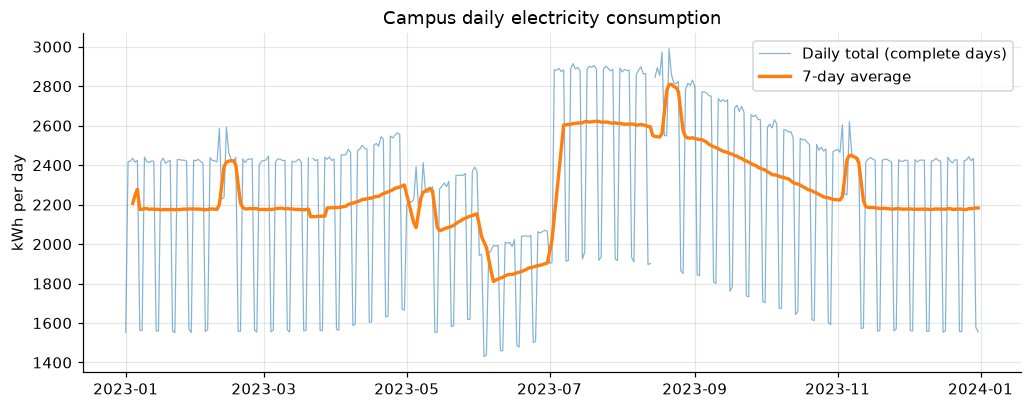

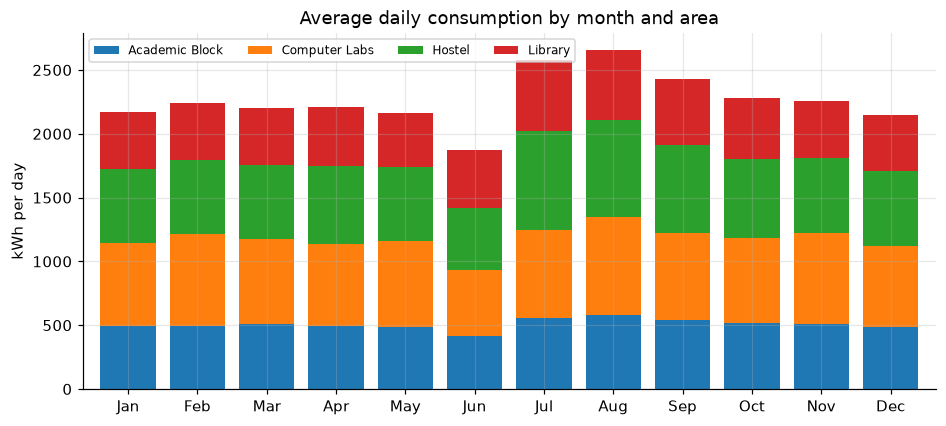

In [9]:
# CHART 2 - daily campus consumption with 7-day average
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(campus_daily.index, campus_daily, lw=0.8, alpha=0.55, label="Daily total (complete days)")
ax.plot(campus_daily.index, campus_daily.rolling(7, min_periods=4).mean(), lw=2.2, label="7-day average")
ax.set(title="Campus daily electricity consumption", ylabel="kWh per day")
ax.legend(); plt.show()

# CHART 3 - monthly average daily consumption by area (stacked)
fig, ax = plt.subplots(figsize=(10, 4.2))
plot_df = avg_daily[areas].copy(); plot_df.index = plot_df.index.strftime("%b")
plot_df.plot(kind="bar", stacked=True, ax=ax, width=0.8)
ax.set(title="Average daily consumption by month and area", xlabel="", ylabel="kWh per day")
ax.tick_params(axis="x", rotation=0); ax.legend(ncol=4, fontsize=8); plt.show()

## 4 · Weekday vs weekend patterns

In [10]:
daytype_daily = np.where(dv.index.dayofweek >= 5, "Weekend", "Weekday")
wk = dv.groupby(daytype_daily).mean().T
wk["Weekend vs weekday (%)"] = (wk["Weekend"] / wk["Weekday"] - 1) * 100
print("Average kWh per complete day")
wk

Average kWh per complete day


C:\Users\Administrator\AppData\Local\Temp\ipykernel_9064\2068505196.py:1: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  daytype_daily = np.where(dv.index.dayofweek >= 5, "Weekend", "Weekday")


,Weekday,Weekend,Weekend vs weekday (%)
area,,,
Academic Block,612.1,242.9,-60.3
Computer Labs,778.7,402.1,-48.4
Hostel,602.8,660.0,9.5
Library,504.4,390.9,-22.5
Campus,"2,497.4","1,695.9",-32.1


C:\Users\Administrator\AppData\Local\Temp\ipykernel_9064\3857690221.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  daytype = np.where(kw.index.dayofweek >= 5, "Weekend", "Weekday")


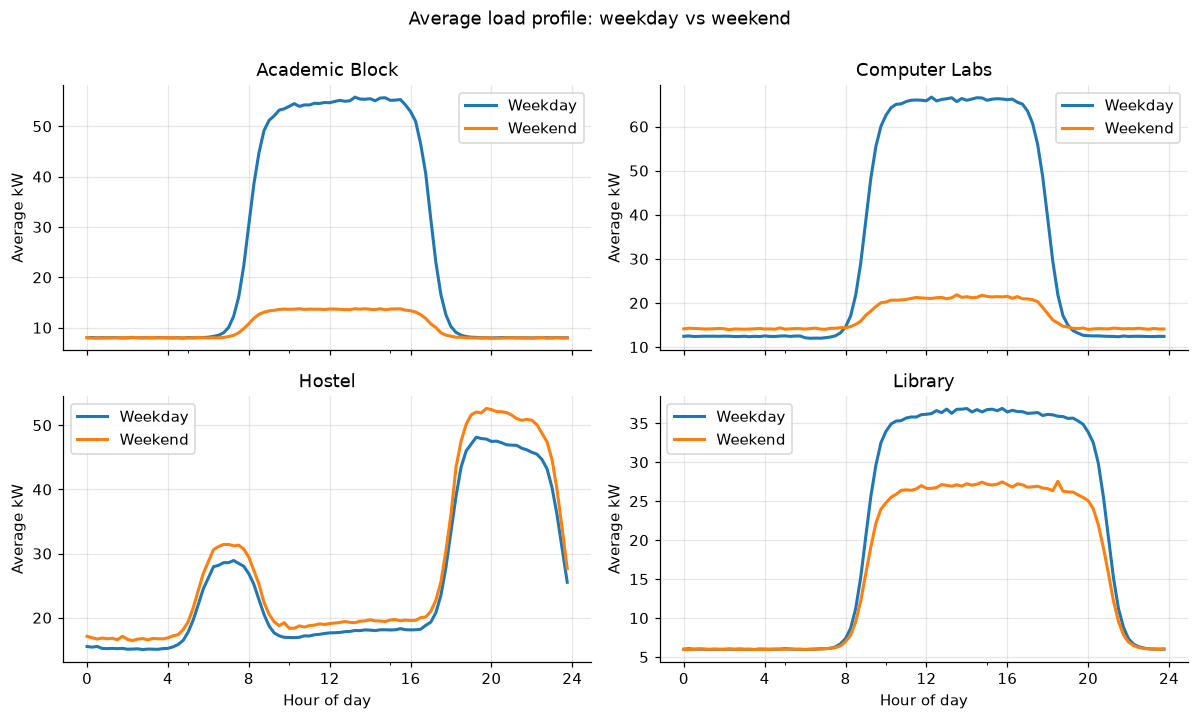

In [11]:
# CHART 4 - average load profile (kW) by time of day, weekday vs weekend, per area
kw = filled * KW_FACTOR
slot_hour = kw.index.hour + kw.index.minute / 60
daytype = np.where(kw.index.dayofweek >= 5, "Weekend", "Weekday")

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True)
for ax, area in zip(axes.ravel(), areas):
    prof = kw[area].groupby([daytype, slot_hour]).mean().unstack(0)
    prof.plot(ax=ax, lw=2)
    ax.set(title=area, xlabel="Hour of day", ylabel="Average kW", xticks=range(0, 25, 4))
fig.suptitle("Average load profile: weekday vs weekend", y=1.00)
plt.tight_layout(); plt.show()

C:\Users\Administrator\AppData\Local\Temp\ipykernel_9064\3154243625.py:3: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  heat = campus_kw.groupby([campus_kw.index.dayofweek, campus_kw.index.hour]).mean().unstack(0)


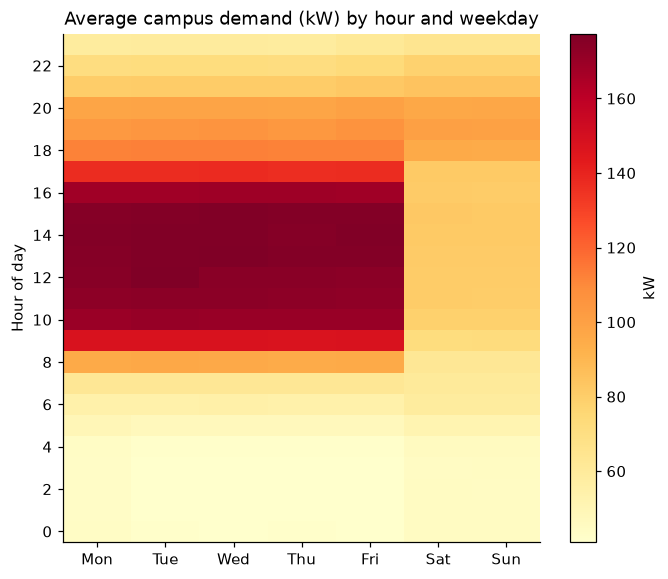

In [12]:
# CHART 5 - when is the campus busiest? hour x weekday heatmap (campus kW)
campus_kw = kw.sum(axis=1, min_count=len(areas))            # only intervals where all areas present
heat = campus_kw.groupby([campus_kw.index.dayofweek, campus_kw.index.hour]).mean().unstack(0)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(heat.values, aspect="auto", origin="lower", cmap="YlOrRd")
ax.set_xticks(range(7)); ax.set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_yticks(range(0, 24, 2)); ax.grid(False)
ax.set(title="Average campus demand (kW) by hour and weekday", ylabel="Hour of day")
fig.colorbar(im, ax=ax, label="kW"); plt.show()

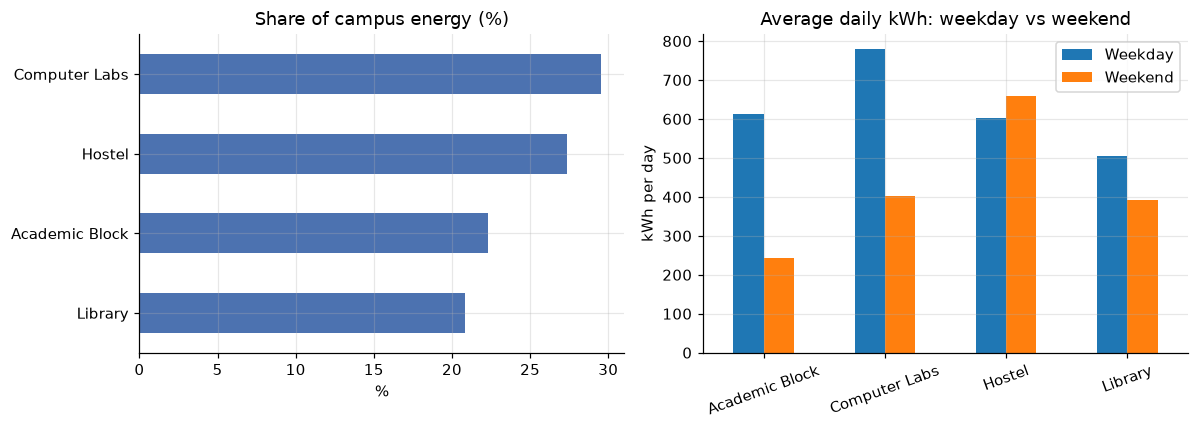

area
Academic Block   22.3
Computer Labs    29.6
Hostel           27.3
Library          20.8


In [13]:
# CHART 6 - comparing areas: share of energy and weekend/weekday ratio
complete_all = dv[areas].dropna()
share = complete_all.mean() / complete_all.mean().sum() * 100

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
share.sort_values().plot(kind="barh", ax=a1, color="#4c72b0")
a1.set(title="Share of campus energy (%)", xlabel="%", ylabel="")
wk.loc[areas, ["Weekday", "Weekend"]].plot(kind="bar", ax=a2)
a2.set(title="Average daily kWh: weekday vs weekend", ylabel="kWh per day", xlabel="")
a2.tick_params(axis="x", rotation=20); plt.tight_layout(); plt.show()
print(share.round(1).to_string())

## 5 · Peak-use periods
Demand is expressed as **average kW per 15-min interval** (kWh × 4). "Peak periods" = the top 1 % of campus intervals.

In [14]:
peak_ts, peak_val, avg_kw = campus_kw.idxmax(), campus_kw.max(), campus_kw.mean()
thr = campus_kw.quantile(0.99)
top = campus_kw[campus_kw >= thr]
hour_counts = top.index.hour.value_counts().reindex(range(24), fill_value=0)
monthly_peak = campus_kw.resample("MS").quantile(0.99)   # robust: one spike cannot set the month
monthly_avg  = campus_kw.resample("MS").mean()

print(f"Campus average demand : {avg_kw:,.1f} kW")
print(f"Highest single interval: {peak_val:,.1f} kW on {peak_ts:%a %d %b %Y %H:%M}  (check §6: single readings can be spikes)")
print(f"Top-1% threshold      : {thr:,.1f} kW  ({len(top)} intervals)")
print(f"Peak intervals on weekdays: {(top.index.dayofweek < 5).mean()*100:.0f}%")
print(f"Busiest hours (top-1% intervals): {hour_counts.nlargest(3).index.tolist()}")
print(f"Month with highest 99th-percentile demand: {monthly_peak.idxmax():%B}  ({monthly_peak.max():,.0f} kW)")
print(f"Load factor (average / highest interval): {avg_kw/peak_val:.2f}")

Campus average demand : 94.4 kW
Highest single interval: 332.7 kW on Tue 14 Feb 2023 12:15  (check §6: single readings can be spikes)
Top-1% threshold      : 207.9 kW  (350 intervals)
Peak intervals on weekdays: 100%
Busiest hours (top-1% intervals): [14, 15, 13]
Month with highest 99th-percentile demand: July  (216 kW)
Load factor (average / highest interval): 0.28


C:\Users\Administrator\AppData\Local\Temp\ipykernel_9064\1099577982.py:11: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  print(f"Peak intervals on weekdays: {(top.index.dayofweek < 5).mean()*100:.0f}%")


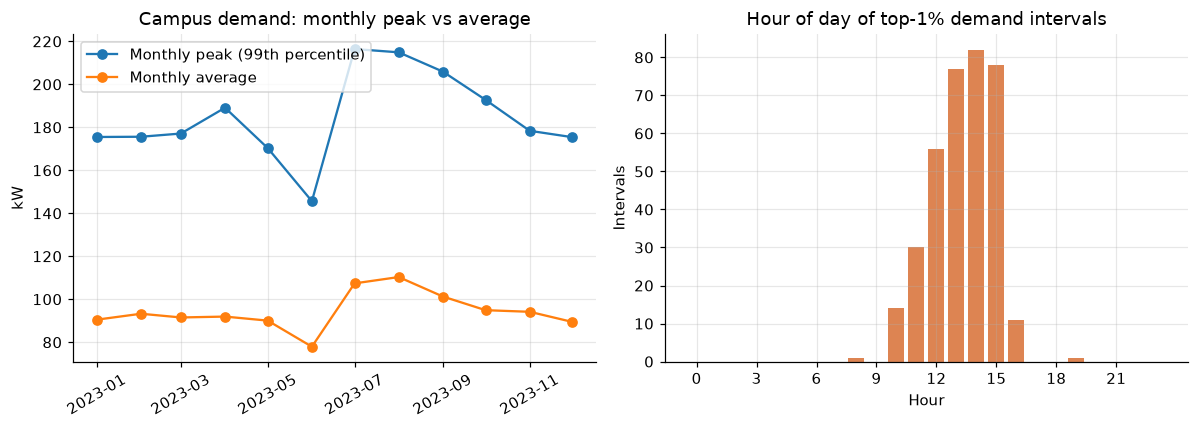

In [15]:
# CHART 7 - peak demand by month, and which hours produce the peaks
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot(monthly_peak.index, monthly_peak, marker="o", label="Monthly peak (99th percentile)")
a1.plot(monthly_avg.index, monthly_avg, marker="o", label="Monthly average")
a1.set(title="Campus demand: monthly peak vs average", ylabel="kW"); a1.legend()
a1.tick_params(axis="x", rotation=30)
a2.bar(hour_counts.index, hour_counts.values, color="#dd8452")
a2.set(title="Hour of day of top-1% demand intervals", xlabel="Hour", ylabel="Intervals", xticks=range(0, 24, 3))
plt.tight_layout(); plt.show()

## 6 · Unusual readings (outlier inspection)

**Method.** For every area, each reading is compared with the *typical* reading for the **same time of day and same day type** (weekday/weekend) using a robust z-score (median and MAD, so the outliers themselves don't distort the baseline).
A reading is flagged if `z > 6` **and** it is at least 2× the typical value (the ratio guard avoids flagging mild, weather-driven variation). Flagged intervals are grouped into **events**; ≥ 1 hour in a row = *sustained*, otherwise *isolated spike*.

Flagged readings are **inspected, not deleted** – a spike could be a faulty meter *or* a real equipment problem.

In [16]:
slot = kw.index.hour * 4 + kw.index.minute // 15
keys = [slot, daytype]
typical = pd.DataFrame(index=filled.index, columns=areas, dtype=float)
zscore  = pd.DataFrame(index=filled.index, columns=areas, dtype=float)
for area in areas:
    s = filled[area]
    med = s.groupby(keys).transform("median")
    mad = (s - med).abs().groupby(keys).transform("median").clip(lower=1e-3)
    typical[area] = med
    zscore[area] = 0.6745 * (s - med) / mad

flags = (zscore > Z_THRESH) & (filled > MIN_RATIO * typical)

rows = []
for area in areas:
    m = flags[area]
    if not m.any():
        continue
    d = pd.DataFrame({"kwh": filled.loc[m, area], "typical": typical.loc[m, area]})
    d.index.name = "timestamp"; d = d.reset_index()
    d["event"] = (d["timestamp"].diff() > pd.Timedelta("1h")).cumsum()
    g = d.groupby("event").agg(start=("timestamp", "min"), end=("timestamp", "max"),
                               n=("kwh", "size"), peak_kwh=("kwh", "max"),
                               actual=("kwh", "sum"), typical=("typical", "sum"))
    g["area"] = area
    rows.append(g)

events = pd.concat(rows, ignore_index=True)
events["duration_h"] = events["n"] * 0.25
events["excess_kwh"] = events["actual"] - events["typical"]
events["type"] = np.where(events["n"] >= SUSTAINED_MIN_INTERVALS, "Sustained (>=1h)", "Isolated spike")

print("Events by area and type:")
print(events.groupby(["area", "type"]).size().unstack(fill_value=0).to_string())
print("\nLargest events by energy above typical (kWh):")
events.sort_values("excess_kwh", ascending=False).head(8)[
    ["area", "type", "start", "end", "duration_h", "peak_kwh", "excess_kwh"]]

Events by area and type:
type            Isolated spike  Sustained (>=1h)
area                                            
Academic Block               8                 0
Computer Labs                8                 4
Hostel                       8                 0
Library                      8                 0

Largest events by energy above typical (kWh):


,area,type,start,end,duration_h,peak_kwh,excess_kwh
13,Computer Labs,Sustained (>=1h),2023-08-18 19:00:00,2023-08-21 05:45:00,59.0,13.9,"1,711.6"
10,Computer Labs,Sustained (>=1h),2023-05-05 19:00:00,2023-05-08 05:45:00,59.0,12.9,"1,645.7"
17,Computer Labs,Sustained (>=1h),2023-11-03 19:00:00,2023-11-06 05:45:00,59.0,12.8,"1,623.8"
8,Computer Labs,Sustained (>=1h),2023-02-10 19:00:00,2023-02-13 05:45:00,58.8,12.3,"1,620.7"
22,Hostel,Isolated spike,2023-08-16 19:15:00,2023-08-16 19:15:00,0.2,55.0,43.6
9,Computer Labs,Isolated spike,2023-02-14 12:15:00,2023-02-14 12:15:00,0.2,57.8,40.9
4,Academic Block,Isolated spike,2023-08-31 16:45:00,2023-08-31 16:45:00,0.2,43.5,33.5
3,Academic Block,Isolated spike,2023-08-22 08:45:00,2023-08-22 08:45:00,0.2,44.3,32.1


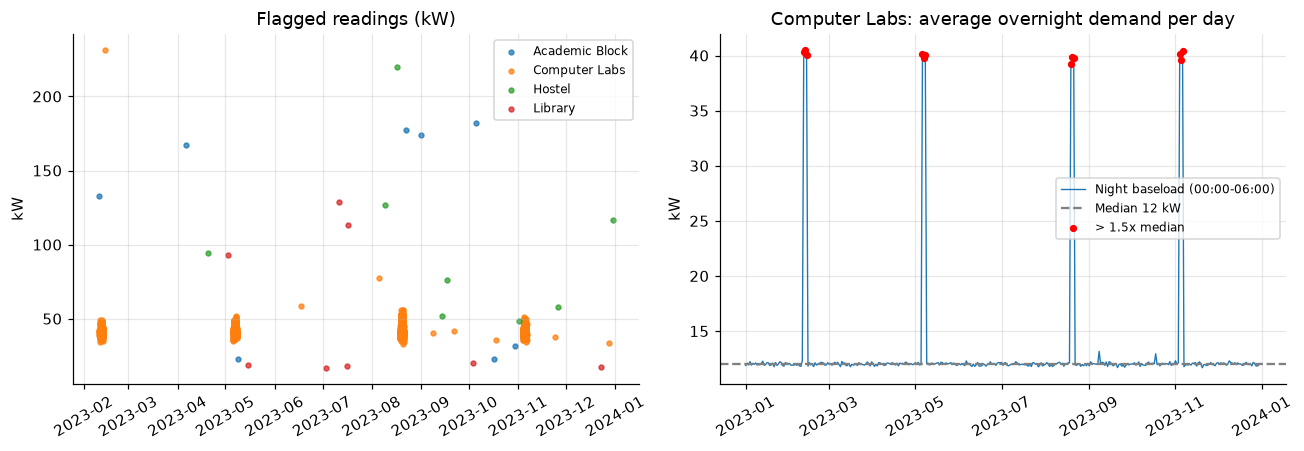

Computer Labs: 12 nights above 1.5x median: ['Sat 11 Feb', 'Sun 12 Feb', 'Mon 13 Feb', 'Sat 06 May', 'Sun 07 May', 'Mon 08 May', 'Sat 19 Aug', 'Sun 20 Aug', 'Mon 21 Aug', 'Sat 04 Nov', 'Sun 05 Nov', 'Mon 06 Nov']


In [17]:
# CHART 8 - flagged readings and the night-time baseload of the Computer Labs
pts = pd.concat([pd.DataFrame({"kw": filled.loc[flags[a], a] * KW_FACTOR, "area": a}) for a in areas])

night = (filled.between_time("00:00", "05:45") * KW_FACTOR).resample("D").mean()
lab = "Computer Labs"
lab_median = night[lab].median()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
for a in areas:
    p = pts[pts.area == a]
    a1.scatter(p.index, p.kw, s=10, label=a, alpha=0.75)
a1.set(title="Flagged readings (kW)", ylabel="kW"); a1.legend(fontsize=8); a1.tick_params(axis="x", rotation=30)

a2.plot(night.index, night[lab], lw=0.9, label="Night baseload (00:00-06:00)")
a2.axhline(lab_median, color="grey", ls="--", label=f"Median {lab_median:.0f} kW")
high = night[lab] > 1.5 * lab_median
a2.scatter(night.index[high], night.loc[high, lab], color="red", s=14, label="> 1.5x median", zorder=3)
a2.set(title=f"{lab}: average overnight demand per day", ylabel="kW"); a2.legend(fontsize=8)
a2.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
print(f"{lab}: {high.sum()} nights above 1.5x median:", [d.strftime('%a %d %b') for d in night.index[high]][:12])

## 7 · Key findings

In [18]:
top_area = share.idxmax()
wk_gap = wk.loc[areas, "Weekend vs weekday (%)"]
low_month = avg_daily["Campus"].idxmin(); high_month = avg_daily["Campus"].idxmax()
sust = events[events["type"].str.startswith("Sustained")]

print(f"1. Estimated campus use in 2023: {est_total['Campus'].sum():,.0f} kWh "
      f"(avg {campus_daily.mean():,.0f} kWh/day on complete days).")
print(f"2. {top_area} is the largest consumer ({share.max():.0f}% of campus energy).")
print(f"3. Highest-use month: {high_month:%B} ({avg_daily.loc[high_month,'Campus']:,.0f} kWh/day); "
      f"lowest: {low_month:%B} ({avg_daily.loc[low_month,'Campus']:,.0f} kWh/day).")
print(f"4. Weekend vs weekday daily use: "
      + "; ".join(f"{a} {v:+.0f}%" for a, v in wk_gap.items()) + ".")
print(f"5. Campus demand averages {avg_kw:,.0f} kW; the top 1% of intervals start at {thr:,.0f} kW. "
      f"{(top.index.dayofweek<5).mean()*100:.0f}% of them fall on weekdays, "
      f"mostly around hours {hour_counts.nlargest(3).index.tolist()}.")
spike_areas = [a for a in areas if flags.loc[peak_ts, a]]
if spike_areas:
    print(f"   Note: the single highest interval ({peak_val:,.0f} kW, {peak_ts:%d %b %H:%M}) contains a flagged "
          f"spike in {', '.join(spike_areas)}, so use the top-1% level, not that one reading, for planning.")
print(f"6. {len(events)} unusual events flagged: {(events['type']=='Isolated spike').sum()} isolated spikes "
      f"and {len(sust)} sustained events "
      f"({', '.join(sorted(sust['area'].unique())) or 'none'}).")
print(f"7. Sustained events used about {sust['excess_kwh'].sum():,.0f} kWh more than the typical level "
      f"for those same hours.")

1. Estimated campus use in 2023: 827,240 kWh (avg 2,266 kWh/day on complete days).
2. Computer Labs is the largest consumer (30% of campus energy).
3. Highest-use month: August (2,648 kWh/day); lowest: June (1,870 kWh/day).
4. Weekend vs weekday daily use: Academic Block -60%; Computer Labs -48%; Hostel +9%; Library -22%.
5. Campus demand averages 94 kW; the top 1% of intervals start at 208 kW. 100% of them fall on weekdays, mostly around hours [14, 15, 13].
   Note: the single highest interval (333 kW, 14 Feb 12:15) contains a flagged spike in Computer Labs, so use the top-1% level, not that one reading, for planning.
6. 36 unusual events flagged: 32 isolated spikes and 4 sustained events (Computer Labs).
7. Sustained events used about 6,602 kWh more than the typical level for those same hours.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_9064\1398884412.py:14: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  f"{(top.index.dayofweek<5).mean()*100:.0f}% of them fall on weekdays, "


## 8 · Energy-saving questions to investigate
These are **questions for the facility team**, not conclusions. The data shows *when* and *where*; it cannot show *why*.

1. **Computer Labs – overnight/weekend load.** Several Friday-night-to-Monday-morning periods show demand far above the normal overnight level. Were machines, servers or HVAC left running? Is there a shutdown policy and who owns it?
2. **Baseload everywhere.** What is the minimum demand at 03:00 in each area, and which equipment explains it (lighting, standby loads, refrigeration, servers)?
3. **Hostel evening peak.** The Hostel peaks in the evening, when campus demand is already high. Could any load (water heating, laundry, charging) be shifted or scheduled?
4. **Weekend operating hours.** The Library and Academic Block still draw power on weekends. Are HVAC and lighting schedules matched to actual opening hours?
5. **Summer cooling.** Use rises in hot months. How much of this is cooling, what are the thermostat set-points, and is cooling running in unoccupied zones?
6. **Break periods (May–June).** Use falls but not to zero. Which buildings could be partly shut down or consolidated during breaks?
7. **Isolated spikes.** Are they meter/communication faults, or real events (equipment start-up, testing, faults)? Check maintenance logs for the timestamps listed above.
8. **Data gaps.** What caused the missing intervals (e.g. the Hostel full-day outage, the Library gap)? A monitoring alert for missing data would prevent blind spots.
9. **Sub-metering.** Would separate meters for HVAC, lighting and plug loads in the largest area make the next analysis actionable?

## 9 · Savings scenario (illustrative – assumptions stated)
The brief says **not to estimate savings without stated assumptions**, so the only figure below is a clearly labelled *what-if* for one question (#1). It is not a forecast.

| Assumption | Value |
|---|---|
| Scope | Sustained (≥ 1 h) unusual events in **Computer Labs** found in this dataset |
| Share of that excess that a shutdown routine could remove (**assumed**) | 50 % |
| Tariff / cost | **Not provided → no cost estimate is made** (kWh only) |
| Pattern repeats at the same rate next year | Assumed, unverified |

In [19]:
ASSUMED_PREVENTABLE_SHARE = 0.50          # <- assumption, change to test other values
lab_events = sust[sust["area"] == "Computer Labs"]
excess = lab_events["excess_kwh"].sum()

print(f"Computer Labs sustained events found      : {len(lab_events)}")
print(f"Energy above typical during those events  : {excess:,.0f} kWh")
print(f"Illustrative saving at {ASSUMED_PREVENTABLE_SHARE:.0%} preventable  : {excess*ASSUMED_PREVENTABLE_SHARE:,.0f} kWh per year")
print("(what-if only: depends on the assumptions in the table above; no cost estimate)")

Computer Labs sustained events found      : 4
Energy above typical during those events  : 6,602 kWh
Illustrative saving at 50% preventable  : 3,301 kWh per year
(what-if only: depends on the assumptions in the table above; no cost estimate)


## 10 · Limitations
- **Synthetic data** – real campuses have messier patterns; effects here (e.g. the Labs events) were built in to be discoverable.
- Daily and monthly figures use **complete days only**; monthly totals are *estimates* (average complete day × days in month).
- Gaps ≤ 1 h were interpolated; longer gaps were left missing and excluded, not filled.
- Weekday/weekend ignores **public holidays**; the May–June break is visible but not labelled in the data.
- Temperature is available but this notebook does not model it – a natural next step.

## Brief checklist
| Requirement | Where |
|---|---|
| Confirm units & sampling interval | §1 |
| Handle missing intervals carefully | §2 |
| Aggregate by day / month | §3 |
| ≥ 4 charts (line / bar / heatmap) | Charts 1–8 |
| Weekday vs weekend; compare areas | §4 |
| Peak periods | §5 |
| Unusual readings | §6 |
| Energy-saving questions | §8 |
| Savings only with stated assumptions | §9 |